In [82]:
import tensorflow as tf
from tensorflow import keras
print("TensorFlow version:", tf.__version__, "\nKeras version:", keras.__version__)

TensorFlow version: 2.21.0 
Keras version: 3.15.1


# Load Data


In [83]:
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [84]:
type(X_train), type(y_train), type(X_test), type(y_test)

(numpy.ndarray, numpy.ndarray, numpy.ndarray, numpy.ndarray)

In [85]:
X_train.shape, X_train.dtype

((60000, 28, 28), dtype('uint8'))

In [86]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

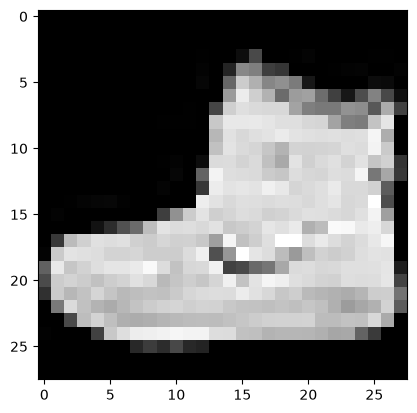

In [87]:
import matplotlib.pyplot as plt
plt.imshow(X_train[0], cmap='gray')

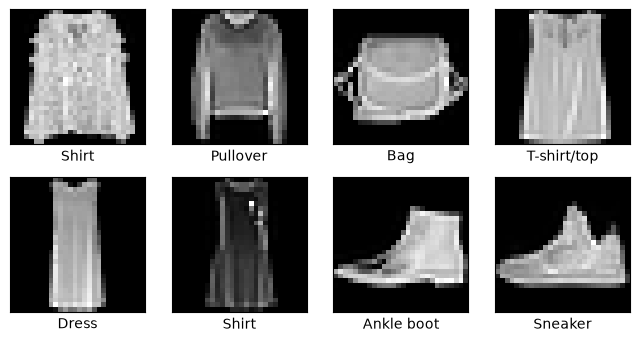

In [88]:
import numpy as np
import random
def plot_data(x_data: np.ndarray, y_data: np.ndarray) -> None:
    nrows,ncols = 2, 4
    fig, axes = plt.subplots(nrows, ncols, figsize=(8,4))

    len_x = len(x_data)
    for idx in range(nrows*ncols):
        ax = axes[idx//ncols, idx%ncols]
        imd_idx = random.randint(0, len_x)
        ax.imshow(x_data[imd_idx], cmap='gray')
        ax.set(xticks=[], yticks=[])
        ax.set_xlabel(class_names[y_data[imd_idx]])

plot_data(X_train, y_train)


# Image Processing

In [89]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0


In [90]:
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)
X_train.shape

(60000, 28, 28, 1)

In [91]:
y_train_label = keras.utils.to_categorical(y_train, num_classes=len(class_names))
y_test_label = keras.utils.to_categorical(y_test, num_classes=len(class_names))

# Network Architecture


In [92]:
from tensorflow.keras import layers, models
input_shape = (28, 28, 1)
class_num = len(class_names)
model = models.Sequential([
    layers.Flatten(input_shape = input_shape), # (28, 28, 1) -> (28*28*1)
    layers.Dense(512,activation='relu'),
    layers.Dense(256,activation='relu'),
    layers.Dense(class_num,activation='softmax')
])
model.summary()

f:\Chunwan\SourceCode\DeepLearning\dl_learn_tensor_flow\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

In [93]:
model.compile(optimizer='rmsprop', loss='categorical_crossentropy', metrics=['accuracy'])

In [94]:
epochs = 50
batch_size=256
history = model.fit(X_train, y_train_label, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7682 - loss: 0.6369 - val_accuracy: 0.8413 - val_loss: 0.4294
Epoch 2/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8454 - loss: 0.4164 - val_accuracy: 0.8410 - val_loss: 0.4522
Epoch 3/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8651 - loss: 0.3632 - val_accuracy: 0.8715 - val_loss: 0.3436
Epoch 4/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8771 - loss: 0.3296 - val_accuracy: 0.8582 - val_loss: 0.3964
Epoch 5/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8868 - loss: 0.3046 - val_accuracy: 0.8755 - val_loss: 0.3396
Epoch 6/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8911 - loss: 0.2880 - val_accuracy: 0.8853 - val_loss: 0.3154
Epoch 7/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8963 - loss: 0.2739 - val_accuracy: 0.8820 - val_loss: 0.3309
Epoch 8/50
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9031 - loss: 0.2589 - val_accuracy: 0.

In [95]:
history_dict = history.history
history_dict.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [96]:
train_loss, val_loss = history_dict['loss'], history_dict['val_loss']
train_acc, val_acc = history_dict['accuracy'], history_dict['val_accuracy']

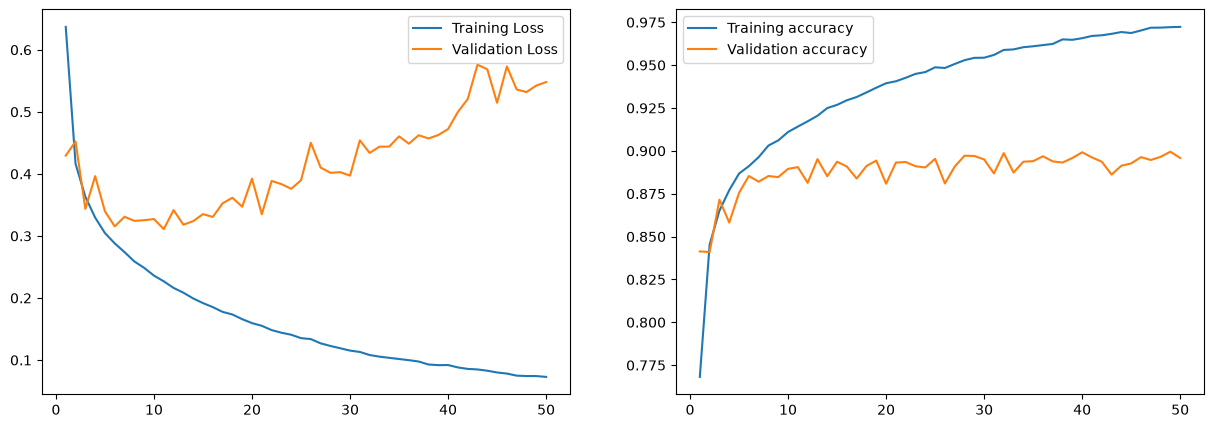

In [97]:
fig, (ax1, ax2) = plt.subplots(1,2,figsize = (15,5))
epoch_runs = [i+1 for i in range(epochs)]

ax1.plot(epoch_runs,train_loss, label = 'Training Loss')
ax1.plot(epoch_runs,val_loss, label = 'Validation Loss')

ax2.plot(epoch_runs,train_acc, label = 'Training accuracy')
ax2.plot(epoch_runs,val_acc, label = 'Validation accuracy')
ax1.legend()
ax2.legend()
plt.show()


# Model evaluetion

In [98]:
score = model.evaluate(X_test, y_test_label)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8946 - loss: 0.5998


In [99]:
print("Test loss:",round(score[0],4),"\nTest accuracy",round(score[1],4))

Test loss: 0.5998 
Test accuracy 0.8946


# Prediction

In [100]:
X_sample = X_test[:10]
y_proba = model.predict(X_sample)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


In [101]:
predictions = np.argmax(y_proba,axis=1)

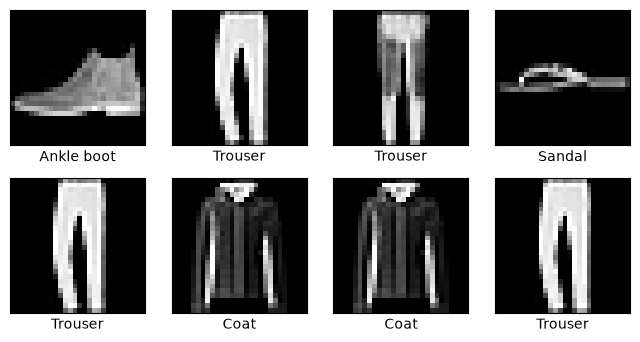

In [102]:
[class_names[pred] for  pred in predictions]
plot_data(X_sample,[pred for  pred in predictions])